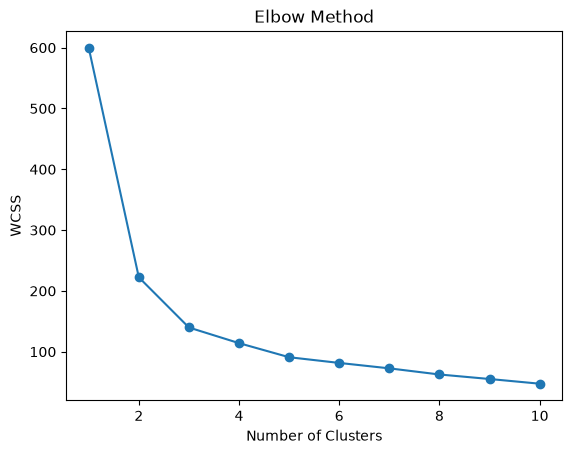

  species  KMeans  Hierarchical
0  setosa       1             1
1  setosa       1             1
2  setosa       1             1
3  setosa       1             1
4  setosa       1             1

Cluster Counts:
KMeans
0    53
1    50
2    47
Name: count, dtype: int64


In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

# Load dataset using Seaborn
df = sns.load_dataset("iris")
X = StandardScaler().fit_transform(df.select_dtypes("number"))

# Elbow method
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# K-Means clustering (choose K from elbow graph)
df["KMeans"] = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X)

# Hierarchical clustering
df["Hierarchical"] = AgglomerativeClustering(n_clusters=3).fit_predict(X)

print(df[["species", "KMeans", "Hierarchical"]].head())
print("\nCluster Counts:")
print(df["KMeans"].value_counts())